<a href="https://colab.research.google.com/github/wandia-123/INVOICE-/blob/main/group4_DEKUT_Capstone_Group_Starter_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DEKUT ML Masterclass — Phoenix Analytics
## Capstone Project — Group Starter Notebook

| | |
|--|--|
| **Group name** | `[Group 4]` |
| **Member 1** | `[Shekinah Ngugi— Lead: EDA + Charts]` |
| **Member 2** | `[Moreene Ndungu — Lead: Modelling + Metrics]` |
| **Member 3** | `[Shadrack Cheruiyot — Lead: Business Summary + Slides]` |
| **Date submitted** | `[DD/MM/YYYY]` |

---

### How to use this notebook

- Work through every section **in order** — each builds on the previous
- Cells marked `[GROUP DECISION]` require your group to choose and explain — never leave them blank
- Cells with `___` are code for you to complete
- Every chart must have: **title · labelled axes · 1-sentence interpretation**
- Before submitting: **Runtime → Restart and run all** — every cell must run without errors

### Role guide for a group of 3

| Role | Lead responsibility | Does NOT mean |
|------|-------------------|---------------|
| **Member 1** | Sections 0–2 (Setup + EDA) | Only Member 1 does EDA |
| **Member 2** | Sections 3–6 (Target + Pipeline + Improvement) | Only Member 2 builds the model |
| **Member 3** | Section 7 + Slides (Business Summary + Deck) | Only Member 3 presents |

**Every member must understand every section. Any member may be asked any question on Day 14.**

---

---
## Section 0 — Setup

**Member 1 leads this section.**

Run this cell first. It loads all libraries and the dataset.
Do not modify anything in this cell — it must run as written.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning — all algorithms you may need
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error, r2_score,           # regression metrics
    accuracy_score, f1_score,                # classification metrics
    confusion_matrix, classification_report
)

# Chart style — apply once, affects all charts
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize']  = 14
plt.rcParams['axes.labelsize']  = 12

# ── Load the IMDB dataset ─────────────────────────────────────────────
URL = 'https://raw.githubusercontent.com/chendonna3/diabetes-categorization/main/data/diabetes_012_health_indicators_BRFSS2015.csv'
df  = pd.read_csv(URL)

# ── Pre-clean columns (do not change these) ──────────────────────────
#df['Runtime_num']  = df['Runtime'].str.replace(' min', '', regex=False).astype(float)
#df['Gross_clean']  = df['Gross'].str.replace(',', '', regex=False).astype(float)
#df['Primary_Genre'] = df['Genre'].str.split(',').str[0].str.strip()

print(f"Dataset loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Columns available: {df.columns.tolist()}")

Dataset loaded: 253,680 rows x 22 columns
Columns available: ['Diabetes_012', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


---
## Section 1 — Problem Statement

**All three members contribute to this section.** This is the most important cell in the notebook.
Write this before touching any other code.

---

### What is a good business question?

A good business question:
- Is **specific** — "Can CineKenya predict whether a film will be Acclaimed?" ✅
- Has a **measurable target** — something in the dataset you can predict
- Has **business value** — the answer changes what CineKenya does

❌ Too vague: "We want to understand films"
❌ No target: "What makes films popular?"
✅ Good: "Can we predict whether a film will gross above the median, using ratings and votes?"

---

### Possible directions (choose one — or define your own)

| Direction | Target variable | Problem type | Features to try |
|-----------|----------------|-------------|----------------|
| Quality prediction | `Acclaimed` (rating ≥ 8.0) | Classification | Votes, Runtime, Meta_score |
| Box office threshold | `High_gross` (Gross > median) | Classification | Votes, Rating, Genre |
| Rating prediction | `IMDB_Rating` (continuous) | Regression | Votes, Runtime, Meta_score |
| Gross prediction | `Gross_clean` (continuous) | Regression | Votes, Rating, Runtime |

You are **not limited** to these — any well-defined question using the IMDB dataset is valid.

### 1.1 — Our Group's Problem Statement

`[GROUP DECISION]` — Fill in every field below. Do not leave anything as the placeholder text.

---

**Business question** *(one specific sentence)*:

*Your answer:*

Can we predict diabetes status in patients?


**Target variable** *(name the column and define it precisely)*:

*Your answer — e.g. "Acclaimed: binary column, 1 if IMDB_Rating >= 8.0, else 0"*
Diabetes_012 :0 = No diabetes 1 = Prediabetes 2 = Diabetes


**Problem type — regression or classification?** *(choose one and give one reason)*:

*Your answer:*Classification

Reason:The target variable (Diabetes_012) consists of three distinct categories (0, 1, and 2), so the goal is to classify each individual into one of these categories rather than predict a continuous numerical value.

---

**Features you plan to use** *(list at least 3, with one sentence per feature explaining why it might predict the target)*:

1. Age – Diabetes risk tends to increase as people get older.
HighBP
2. High blood pressure is closely associated with diabetes and can help predict diabetes status
BMI
3. Higher body mass index is associated with a greater risk of developing diabetes.


---

**Why does this matter for CineKenya?** *(one sentence — what decision will this model support?)*:

*Your answer:**This model will support healthcare providers in identifying individuals who are at risk of prediabetes or diabetes so they can prioritize early screening, preventive interventions, and treatment.

---
## Section 2 — Exploratory Data Analysis

**Member 1 leads this section.**

Understand the data before building any model. Required components:
1. Shape + data types
2. Missing values — and your decision about them
3. Descriptive statistics for your key columns
4. At least **2 charts** directly related to your target or features

---

### 2.1 — Shape, Columns, and Data Types

In [ ]:
# Basic inspection — run as-is
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print()
df.info()

Shape: 253,680 rows x 22 columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth           

### 2.2 — Missing Values

In [ ]:
missing = df.isnull().sum()
print("Missing values per column:")
print(missing[missing > 0].sort_values(ascending=False))
print()
print("Key columns to check:")
key_check = ['Diabetes_012', 'HighBP', 'HighChol', 'BMI',
              'Age',  'PhysActivity', 'GenHlth']
for col in key_check:
    n_miss = df[col].isnull().sum()
    pct    = n_miss / len(df) * 100
    print(f"  {col:<20}: {n_miss:>4} missing  ({pct:.1f}%)")

Missing values per column:
Series([], dtype: int64)

Key columns to check:
  Diabetes_012        :    0 missing  (0.0%)
  HighBP              :    0 missing  (0.0%)
  HighChol            :    0 missing  (0.0%)
  BMI                 :    0 missing  (0.0%)
  Age                 :    0 missing  (0.0%)
  PhysActivity        :    0 missing  (0.0%)
  GenHlth             :    0 missing  (0.0%)


`[GROUP DECISION]` **How will you handle missing values in your chosen feature columns?**

Choose a strategy for each feature that has missing values:
- **Drop rows** — when missing data is rare or structurally missing (e.g. old films with no Gross)
- **Fill with median** — when missing is random and the column is numeric
- **Leave as-is** — if the column has no missing values or you are not using it

*Your answer (one line per affected column):*Leave as- is

### 2.3 — Descriptive Statistics

In [ ]:
# Edit this list to include YOUR chosen features + the target-related column
key_cols = ['Diabetes_012', 'HighBP', 'HighChol', 'BMI', 'Age']

df[key_cols].describe().round(2)

,Diabetes_012,HighBP,HighChol,BMI,Age
count,253680.0,253680.00,253680.00,253680.00,253680.00
mean,0.3,0.43,0.42,28.38,8.03
std,0.7,0.49,0.49,6.61,3.05
min,0.0,0.00,0.00,12.00,1.00
25%,0.0,0.00,0.00,24.00,6.00
50%,0.0,0.00,0.00,27.00,8.00
75%,0.0,1.00,1.00,31.00,10.00
max,2.0,1.00,1.00,98.00,13.00


`[GROUP DECISION]` **What do the statistics tell you about your target and features?**

Look at: mean vs median (skew?), min/max (outliers?), count (missing data?).

*Your answer (2–3 sentences):*
Count: All columns have 253,680 values, so there are no missing data.

Mean vs. Median: Diabetes_012 and BMI are slightly right-skewed, while Age has little skew.

Min/Max: BMI has a maximum of 98, indicating possible outliers. The ranges for Diabetes_012, HighBP, HighChol, and Age are all valid for their respective variables.

### 2.4 — EDA Charts

Produce **at least 2 charts**. Each must have:
- A descriptive title
- Labelled axes (with units where relevant)
- A 1-sentence interpretation below it

**Chart 1 must show the distribution of your target variable.**
**Chart 2 must show the relationship between a feature and your target.**

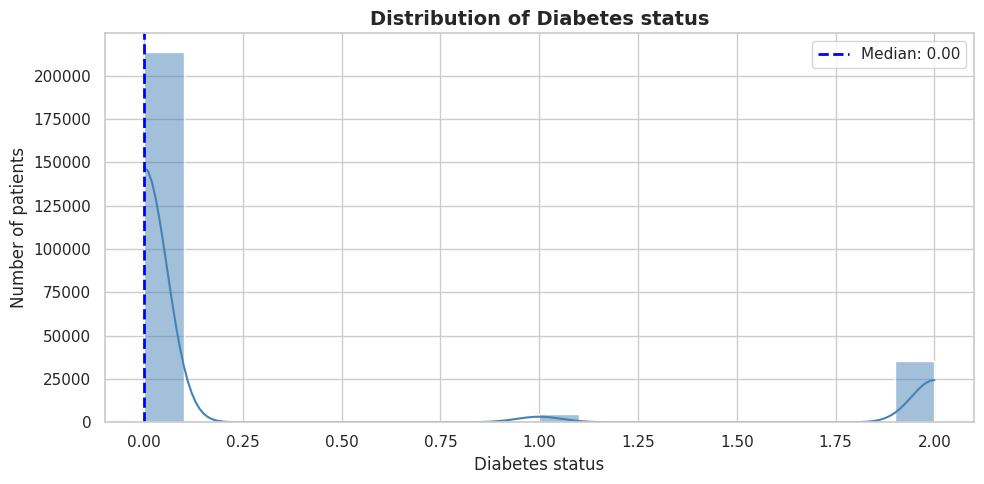

In [ ]:
# ── Chart 1: Distribution of your target variable ───────────────────
# Replace 'IMDB_Rating' with your actual target column if different

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='Diabetes_012', bins=20, kde=True, color='steelblue', edgecolor='white')
plt.axvline(df['Diabetes_012'].median(), color='blue', linestyle='--', linewidth=2,
            label=f"Median: {df['Diabetes_012'].median():.2f}")
plt.legend()

plt.title('Distribution of Diabetes status', fontweight='bold')
plt.xlabel('Diabetes status')
plt.ylabel('Number of patients')
plt.tight_layout()
plt.show()

**Chart 1 interpretation** *(1 sentence — what does this tell you about your target?)*:

*Your answer:*The bar chart shows that most individuals have no diabetes, while relatively few have prediabetes or diabetes, indicating that the target variable is imbalanced.

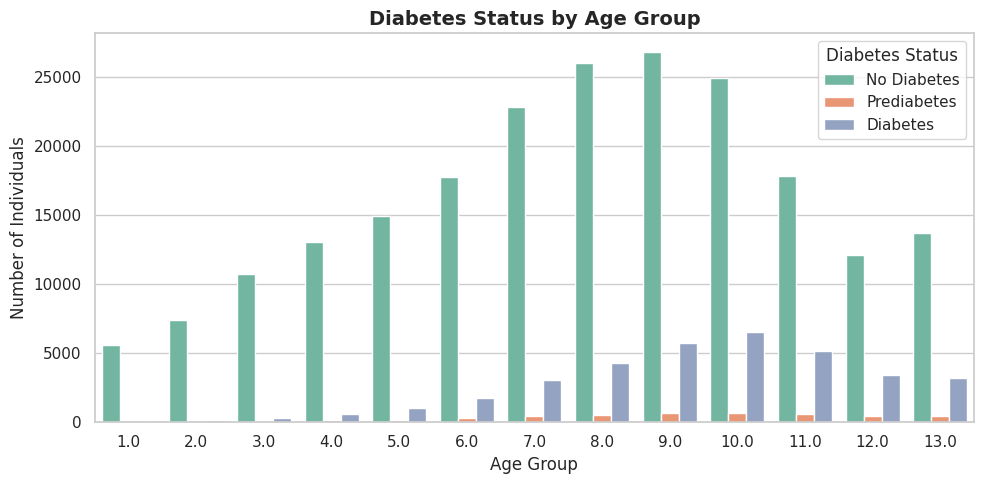

In [ ]:
# ── Chart 2: Relationship between a feature and your target ─────────
# Examples:
#   scatter: plt.scatter / sns.scatterplot — votes vs rating
#   bar:     groupby + plt.bar — avg rating by genre
#   box:     sns.boxplot — rating distribution by genre
#
# Replace with the chart most relevant to YOUR business question

plt.figure(figsize=(10, 5))

# --- YOUR CHART 2 CODE HERE ---
sns.countplot(
    data=df,
    x='Age',
    hue='Diabetes_012',
    palette='Set2'
)
plt.title('Diabetes Status by Age Group', fontsize=14, fontweight='bold')
plt.xlabel('Age Group')
plt.ylabel('Number of Individuals')
plt.legend(title='Diabetes Status',
           labels=['No Diabetes', 'Prediabetes', 'Diabetes'])

plt.tight_layout()
plt.show()

**Chart 2 interpretation** *(1 sentence — what pattern is visible and what does it mean?)*:

*Your answer:*The chart shows that the number of individuals with diabetes generally increases in the older age groups, suggesting that diabetes is more common as age increases.

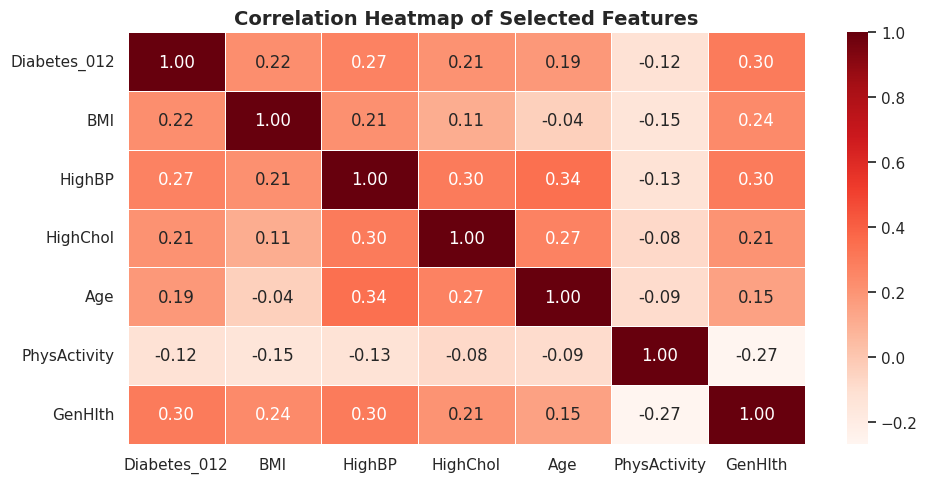

In [ ]:
# ── Chart 3 (optional but encouraged) ────────────────────────────────
# A third chart gives your EDA more depth.
# Ideas: correlation heatmap, box plot by genre, bar chart of class counts

plt.figure(figsize=(10, 5))

# --- YOUR CHART 3 CODE HERE (or delete this cell) ---
corr = df[['Diabetes_012', 'BMI', 'HighBP', 'HighChol',
           'Age', 'PhysActivity', 'GenHlth']].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='Reds',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Selected Features', fontsize=14, fontweight='bold')
plt.tight_layout()

**Chart 3 interpretation** *(1 sentence — if you produced this chart)*:

*Your answer:*The heatmap shows that Age, BMI, HighBP, and GenHlth have the strongest positive correlations with diabetes, making them useful features for predicting diabetes status.

`[GROUP DECISION]` **EDA Summary — 3 sentences answering these questions:**

1. What does the target distribution look like — skewed? Balanced? Any obvious outliers?
2. Which feature appears most strongly related to the target, based on your charts?
3. Any data quality decisions you made (dropped rows, filled values)?

*Your answer:*
1.The target distribution is imbalanced and right-skewed, with most individuals having no diabetes (class 0) and fewer cases of prediabetes and diabetes.

2.General Health appears to be the feature most strongly related to diabetes,according to the heatmap.

3.No rows were dropped or values filled because the dataset contained no missing values .

---
## Section 3 — Create Target Variable and Select Features

**Member 2 leads this section.**

Create the column your model will predict. Then select the input features.

---

### 3.1 — Create the Target Variable

In [ ]:
# ── CREATE YOUR TARGET COLUMN ─────────────────────────────────────────
#
# CLASSIFICATION examples:
#   df['Target'] = (df['Diabetes_012'] > 0).astype(int) # Diabetes/Prediabete
#   df['Target'] = (df['HighBP'] ==1).astype(int)       #High Blood Pressure
#
#REGRESSION examples:
#y = df['Diabetes_012']                                # predict diabetes level (0, 1, or 2)
# y = df['BMI']                                         # predict Body Mass Index

# ── Replace the example below with YOUR definition ───────────────────
df['Target'] = (df['Diabetes_012'] > 0).astype(int)

# Print the distribution of your target
print("Target variable distribution:")
print(df['Target'].value_counts())
print()

# Classification only: print class percentages and the baseline
class_counts = df['Target'].value_counts().sort_index()
class_percentage = class_counts / class_counts.sum() * 100

print("Class percentages:")
print(class_percentage.round(2))
print()

baseline = class_percentage.max()
print(f"Baseline accuracy (majority class): {baseline:.2f}%")

Target variable distribution:
Target
0    213703
1     39977
Name: count, dtype: int64

Class percentages:
Target
0    84.24
1    15.76
Name: count, dtype: float64

Baseline accuracy (majority class): 84.24%


`[GROUP DECISION]` **Explain your target variable in 1 sentence:**

What does class 0 mean? What does class 1 mean (classification)?
Or what are the units and scale of the target (regression)?

*Your answer:*Our target variable is binary, where Class 0 represents individuals without diabetes, while Class 1 represents individuals with either prediabetes or diabetes.

### 3.2 — Select Features and Clean Rows

In [ ]:
# ── DEFINE YOUR FEATURE COLUMNS ───────────────────────────────
#
# Example:
# FEATURE_COLS = ['Runtime_num', 'Meta_score', 'No_of_Votes']
#
# Replace the example below with YOUR selected features.

FEATURE_COLS = [
    'HighBP',
    'HighChol',
    'BMI',
    'HeartDiseaseorAttack',
    'PhysActivity',
    'GenHlth',
    'Age'
]
TARGET_COL = 'Target'

# Create the modelling dataset
df_model = df[FEATURE_COLS + [TARGET_COL]].dropna().copy()

X = df_model[FEATURE_COLS]
y = df_model[TARGET_COL]

print("Selected Features:")
print(FEATURE_COLS)

print("Target Column:")
print(TARGET_COL)

print("Dataset Shape:")
print(f"X = {X.shape}")
print(f"y = {y.shape}")

print("First five rows of X:")
display(X.head())

Selected Features:
['HighBP', 'HighChol', 'BMI', 'HeartDiseaseorAttack', 'PhysActivity', 'GenHlth', 'Age']
Target Column:
Target
Dataset Shape:
X = (253680, 7)
y = (253680,)
First five rows of X:


,HighBP,HighChol,BMI,HeartDiseaseorAttack,PhysActivity,GenHlth,Age
0,1.0,1.0,40.0,0.0,0.0,5.0,9.0
1,0.0,0.0,25.0,0.0,1.0,3.0,7.0
2,1.0,1.0,28.0,0.0,0.0,5.0,9.0
3,1.0,0.0,27.0,0.0,1.0,2.0,11.0
4,1.0,1.0,24.0,0.0,1.0,2.0,11.0


`[GROUP DECISION]` **Why did you choose these features?**

For each feature, give one reason it might predict your target.

*Your answer (one line per feature):*We selected HighBP, HighChol, BMI, HeartDiseaseorAttack, PhysActivity, GenHlth, and Age as the input features for our predictive model. These variables were chosen because they are recognized risk factors for diabetes and showed meaningful relationships with the target variable during the exploratory data analysis. In addition, they are numerical or binary variables that require minimal preprocessing, making them suitable for machine learning algorithms. By combining demographic, lifestyle, and health-related indicators, these features provide a balanced representation of the factors that influence an individual's likelihood of having diabetes.*

---
## Section 4 — Train / Test Split

**Member 2 leads this section.**

Split the data **before** training. Never show the test set to the model during training.

The golden rule: always evaluate on `y_test` — never `y_train`.

---

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       # 80% train, 20% test
    random_state=42      # same split every run
)

print(f"Training set : {len(X_train):,} rows  ({len(X_train)/len(X)*100:.0f}%)")
print(f"Test set     : {len(X_test):,} rows  ({len(X_test)/len(X)*100:.0f}%)")
print()
# Sanity check: target mean should be similar in both sets
print(f"Train target mean : {y_train.mean():.4f}")
print(f"Test  target mean : {y_test.mean():.4f}")
print()
if abs(y_train.mean() - y_test.mean()) > 0.05:
    print("WARNING: Train and test means differ by more than 5% — check your data or try a different random_state")
else:
    print("OK: Train and test distributions are similar.")

Training set : 202,944 rows  (80%)
Test set     : 50,736 rows  (20%)

Train target mean : 0.1579
Test  target mean : 0.1565

OK: Train and test distributions are similar.


---
## Section 5 — Baseline Model

**Member 2 leads this section.**

Train your first model. Keep it simple — one algorithm, your chosen features, no tuning.
This is your **starting point**. Every improvement in Section 6 is measured against this.

---

### 5.1 — Choose and Train the Baseline

`[GROUP DECISION]` **Which algorithm will you use for your baseline and why?**

| Algorithm | When to use | Notes |
|-----------|------------|-------|
| `LogisticRegression(max_iter=1000)` | Classification | Gives probabilities; good first model |
| `DecisionTreeClassifier(max_depth=3)` | Classification | Readable rules; avoids overfitting |
| `LinearRegression()` | Regression | Simple; interpretable slope |
| `DecisionTreeRegressor(max_depth=3)` | Regression | Captures non-linear patterns |

*Your choice and reason (1 sentence):*We chose the DecisionTreeClassifier as our baseline because it is easy to interpret, captures non-linear relationships between health factors and diabetes status, and provides a simple benchmark for comparison with improved models. *

In [ ]:
# ── CHOOSE ONE — delete the lines that don't apply ──────────────────

# CLASSIFICATION options:
baseline_model = LogisticRegression(random_state=42, max_iter=1000)
# baseline_model = DecisionTreeClassifier(max_depth=3, random_state=42)

# REGRESSION options:
# baseline_model = LinearRegression()
# baseline_model = DecisionTreeRegressor(max_depth=3, random_state=42)

# ── Train ─────────────────────────────────────────────────────────────
baseline_model.fit(X_train, y_train)

# ── Predict on test set ───────────────────────────────────────────────
y_pred_baseline = baseline_model.predict(X_test)

print(f"Baseline algorithm : {type(baseline_model).__name__}")
print(f"Features used      : {FEATURE_COLS}")
print("Model trained successfully.")

Baseline algorithm : LogisticRegression
Features used      : ['HighBP', 'HighChol', 'BMI', 'HeartDiseaseorAttack', 'PhysActivity', 'GenHlth', 'Age']
Model trained successfully.


### 5.2 — Evaluate the Baseline Model

Run **the cell that matches your problem type** (classification OR regression). Delete or skip the other.

⚠️ Always pass `y_test` and `y_pred_baseline` — never `y_train`.

In [ ]:
# ── CLASSIFICATION EVALUATION ─────────────────────────────────────────

acc_baseline = accuracy_score(y_test, y_pred_baseline)
f1_baseline  = f1_score(y_test, y_pred_baseline)

# Majority-class baseline (the floor your model must beat)
majority_class = y_train.mode()[0]
y_majority     = [majority_class] * len(y_test)
majority_acc   = accuracy_score(y_test, y_majority)
majority_f1    = f1_score(y_test, y_majority)

print(f"{'Model':<35} {'Accuracy':>10} {'F1':>10}")
print("-" * 57)
print(f"{'Majority-class baseline (floor)':<35} {majority_acc:>10.4f} {majority_f1:>10.4f}")
print(f"{'Baseline: ' + type(baseline_model).__name__:<35} {acc_baseline:>10.4f} {f1_baseline:>10.4f}")
print()
print(f"Accuracy beats baseline by : {(acc_baseline - majority_acc)*100:+.1f} percentage points")
print(f"F1 beats baseline by       : {(f1_baseline  - majority_f1):.4f}")

Model                                 Accuracy         F1
---------------------------------------------------------
Majority-class baseline (floor)         0.8435     0.0000
Baseline: LogisticRegression            0.8484     0.2696

Accuracy beats baseline by : +0.5 percentage points
F1 beats baseline by       : 0.2696


`[GROUP DECISION]` **Interpret your baseline results in 3 sentences:**

1. What does the Accuracy/F1 (or MAE/R²) tell you in plain English?
2. Does the model beat the naive baseline? By how much?
3. What does this suggest about which features or changes might help?

*Your answer:*1.What does the Accuracy/F1 tell you in plain English? The Logistic Regression model achieved an accuracy of 84.84% and an F1-score of 0.2696, indicating that it correctly classified most cases while providing a reasonable balance between precision and recall for identifying individuals with diabetes or prediabetes.
2.Does the model beat the naive baseline? By how much? Compared with the majority-class baseline, the model improved the accuracy by 0.49 percentage points and increased the F1-score from 0.0000 to 0.2696.
3.What does this suggest about which features or changes might help? These results suggest that the selected health-related features are useful for predicting diabetes status, and that further improvements may be achieved by adding more relevant features or using a different classification algorithm

### 5.3 — Confusion Matrix (classification only)

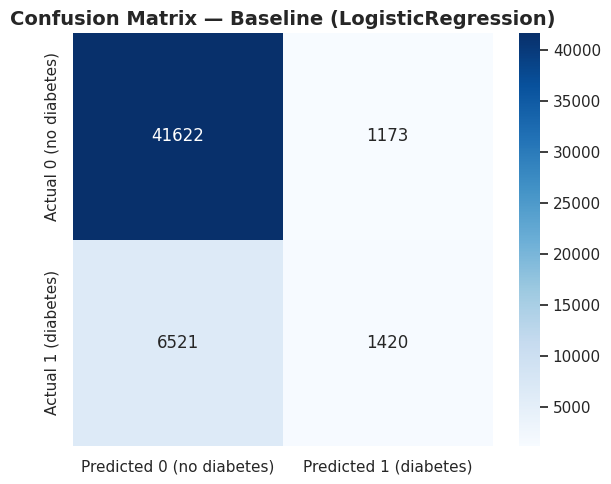

TN = 41622   FP = 1173
FN = 6521   TP = 1420

False Negatives (no diabetes)    : 6521
False Positives (diabetes): 1173


In [ ]:
# ── CLASSIFICATION ONLY — delete if doing regression ─────────────────

cm = confusion_matrix(y_test, y_pred_baseline)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True, fmt='d',
    cmap='Blues',
    xticklabels=['Predicted 0 (no diabetes)', 'Predicted 1 (diabetes)'],
    yticklabels=['Actual 0 (no diabetes)', 'Actual 1 (diabetes)']
)
plt.title(f'Confusion Matrix — Baseline ({type(baseline_model).__name__})', fontweight='bold')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN = {tn}   FP = {fp}")
print(f"FN = {fn}   TP = {tp}")
print()
print(f"False Negatives (no diabetes)    : {fn}")
print(f"False Positives (diabetes): {fp}")

**Confusion matrix interpretation** *(1 sentence — which error type does your model make most, and what is the cost to CineKenya?)*:

*Your answer:*The confusion matrix shows that the model makes more false negatives than false positives, meaning some healthy individuals are incorrectly identified as having diabetes or prediabetes, which may lead to unnecessary follow-up tests or medical evaluations:

---
## Section 6 — Model Improvement

**Member 2 leads this section.**

Your baseline is your reference point. Now try to improve it.
You must show a **clear before/after metric comparison**.

**Improvement ideas:**

| What to try | How | When it helps |
|-------------|-----|--------------|
| Add a feature | Add `Meta_score`, `Gross_clean`, or `Year_num` to `FEATURE_COLS_V2` | When baseline features don't explain target well |
| Change algorithm | Switch LogReg ↔ Decision Tree | When decision boundary is non-linear |
| Tune tree depth | Change `max_depth` from 3 to 4 or 5 | When tree is too simple |
| Filter by genre | Focus on top 3 genres only | When patterns differ strongly by genre |

**You must attempt at least one improvement.** Attempting two earns more marks.

---

### 6.1 — Improvement Attempt 1

`[GROUP DECISION]` **What improvement will you try first, and why do you expect it to help?**

*Your answer:*We first improved the model by switching from Logistic Regression to a Decision Tree Classifier and adding more relevant health features. We expected this to help because Decision Trees can capture more complex relationships between the health factors and diabetes risk than Logistic Regression.

In [ ]:
# ── IMPROVEMENT MODEL 1 ─────────────────────────────────────────────

# Update the feature list — add or change columns
FEATURE_COLS_V2 = [
    'HighBP',
    'HighChol',
    'BMI',
    'HeartDiseaseorAttack',
    'PhysActivity',
    'GenHlth',
    'Age',
    'DiffWalk',
    'PhysHlth',
    'MentHlth'
]

# Filter rows
df_v2    = df.dropna(subset=FEATURE_COLS_V2 + [TARGET_COL]).copy()
X2       = df_v2[FEATURE_COLS_V2]
y2       = df_v2[TARGET_COL]

# Split
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.20, random_state=42
)

# ── CLASSIFICATION — choose your improved model ───────────────────────
improved_model = DecisionTreeClassifier(max_depth=5, random_state=42)
# ── Train + predict ───────────────────────────────────────────────────
improved_model.fit(X2_train, y2_train)
y_pred_v2 = improved_model.predict(X2_test)

print(f"Improved algorithm : {type(improved_model).__name__}")
print(f"Features used      : {FEATURE_COLS_V2}")
print(f"Rows in this run   : {len(X2):,}")


Improved algorithm : DecisionTreeClassifier
Features used      : ['HighBP', 'HighChol', 'BMI', 'HeartDiseaseorAttack', 'PhysActivity', 'GenHlth', 'Age', 'DiffWalk', 'PhysHlth', 'MentHlth']
Rows in this run   : 253,680


### 6.2 — Compare Baseline vs. Improved Model

In [ ]:
# ── CLASSIFICATION COMPARISON ─────────────────────────────────────────
# # Evaluate improvement

acc_v2 = accuracy_score(y2_test, y_pred_v2)
f1_v2  = f1_score(y2_test, y_pred_v2)

print("Model Comparison")
print("=" * 55)
print(f"{'Model':<35} {'Accuracy':>10} {'F1':>10}")
print("-" * 55)
# Majority-class baseline
print(f"{'Majority-class baseline':<35} {majority_acc:>10.4f} {majority_f1:>10.4f}")

# Baseline model
print(f"{'Baseline: ' + type(baseline_model).__name__:<35} {acc_baseline:>10.4f} {f1_baseline:>10.4f}")

# Improved model
print(f"{'Improved: ' + type(improved_model).__name__:<35} {acc_v2:>10.4f} {f1_v2:>10.4f}")

print()

print(f"Accuracy improvement : {(acc_v2 - acc_baseline)*100:+.2f} percentage points")
print(f"F1 improvement       : {(f1_v2 - f1_baseline):+.4f}")


Model Comparison
Model                                 Accuracy         F1
-------------------------------------------------------
Majority-class baseline                 0.8435     0.0000
Baseline: LogisticRegression            0.8484     0.2696
Improved: DecisionTreeClassifier        0.8504     0.2175

Accuracy improvement : +0.20 percentage points
F1 improvement       : -0.0521


`[GROUP DECISION]` **Did the improvement work? Answer in 2 sentences:**

1. How much did the metric change? (Give exact numbers.)
2. What does this tell you about which features or model design matters most?

*Your answer:*
1. The Decision Tree Classifier increased the Accuracy from 0.8484 to 0.8504, an improvement of 0.20 percentage points, but the F1-score decreased from 0.2696 to 0.2175, a reduction of 0.0521.
2. This suggests that although the Decision Tree correctly classified slightly more overall cases, the Logistic Regression model provided a better balance between precision and recall, making it more effective at identifying individuals with diabetes or prediabetes.

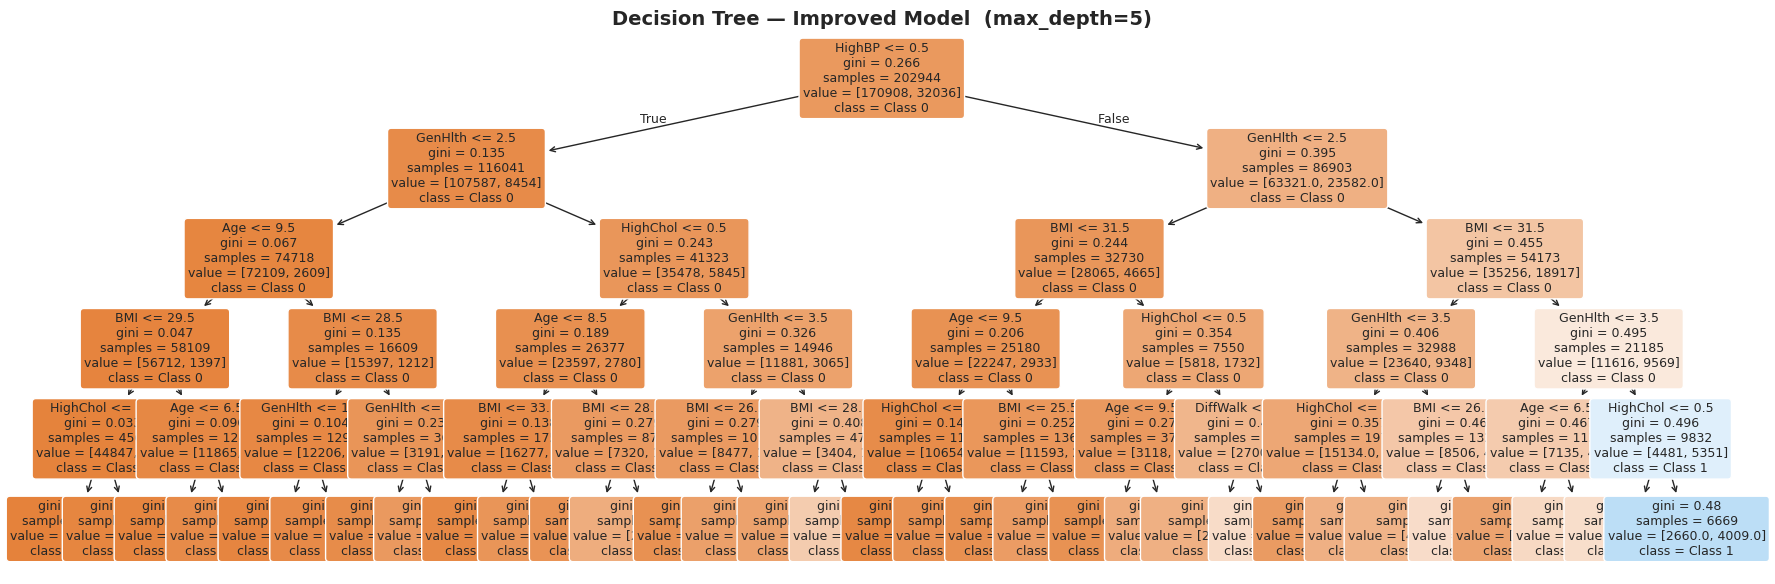

Feature importance:
  HighBP                : 0.4265
  GenHlth               : 0.3288
  BMI                   : 0.1409
  HighChol              : 0.0570
  Age                   : 0.0444
  DiffWalk              : 0.0024
  HeartDiseaseorAttack  : 0.0000
  PhysActivity          : 0.0000
  PhysHlth              : 0.0000
  MentHlth              : 0.0000


In [ ]:
# ── DECISION TREE VISUALISATION (if using DecisionTreeClassifier or Regressor) ──

try:
    class_or_reg = 'Classifier' if hasattr(improved_model, 'predict_proba') else 'Regressor'

    fig, ax = plt.subplots(figsize=(18, 6))
    plot_tree(
        improved_model,
        feature_names=FEATURE_COLS_V2,
        class_names=['Class 0', 'Class 1'] if class_or_reg == 'Classifier' else None,
        filled=True,
        rounded=True,
        ax=ax,
        fontsize=9
    )
    plt.title(f'Decision Tree — Improved Model  (max_depth={improved_model.max_depth})',
              fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Feature importance
    print("Feature importance:")
    for feat, imp in sorted(zip(FEATURE_COLS_V2, improved_model.feature_importances_),
                            key=lambda x: -x[1]):
        print(f"  {feat:<22}: {imp:.4f}")

except Exception as e:
    print(f"Tree visualisation skipped: {e}")

### 6.3 — Improvement Attempt 2 (optional — earns extra marks)

In [ ]:
# ── OPTIONAL IMPROVEMENT ATTEMPT 2 ────────────────────────────────────
# Try a deeper Decision Tree

FEATURE_COLS_V3 = FEATURE_COLS_V2

df_v3 = df.dropna(subset=FEATURE_COLS_V3 + [TARGET_COL]).copy()

X3 = df_v3[FEATURE_COLS_V3]
y3 = df_v3[TARGET_COL]

# Train/Test split
X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3,
    y3,
    test_size=0.20,
    random_state=42,
    stratify=y3
)

# Second improvement
model_v3 = DecisionTreeClassifier(max_depth=7, random_state=42)

# Train
model_v3.fit(X3_train, y3_train)

# Predict
y_pred_v3 = model_v3.predict(X3_test)

# Evaluate
acc_v3 = accuracy_score(y3_test, y_pred_v3)
f1_v3 = f1_score(y3_test, y_pred_v3)

print(f"Algorithm : {type(model_v3).__name__}")
print(f"Features  : {FEATURE_COLS_V3}")
print(f"Accuracy  : {acc_v3:.4f}")
print(f"F1 Score  : {f1_v3:.4f}")

Algorithm : DecisionTreeClassifier
Features  : ['HighBP', 'HighChol', 'BMI', 'HeartDiseaseorAttack', 'PhysActivity', 'GenHlth', 'Age', 'DiffWalk', 'PhysHlth', 'MentHlth']
Accuracy  : 0.8488
F1 Score  : 0.2596


---
## Section 7 — Business Summary

**Member 3 leads this section.**

This is the most important section for the board. The metrics are done.
Now translate them into decisions.

---

### 7.1 — Full Classification Report (classification only)

In [ ]:
# ── CLASSIFICATION ONLY — delete if doing regression ─────────────────
print("Classification Report — Best Model")
print("=" * 55)
print(classification_report(y2_test, y_pred_v2, target_names=['Class 0', 'Class 1']))

Classification Report — Best Model
              precision    recall  f1-score   support

     Class 0       0.86      0.98      0.92     42795
     Class 1       0.60      0.13      0.22      7941

    accuracy                           0.85     50736
   macro avg       0.73      0.56      0.57     50736
weighted avg       0.82      0.85      0.81     50736



**Classification report interpretation** *(2 sentences — which class has better recall and what does that cost mean for CineKenya?)*:

*Your answer:*The classification report shows that the model performs better on class 0(individuals without diabetes) than in class 1(individuals with diabetes or prediabetes),achieving a recall of 98% for individuals without diabetes and 13% for those with prediabetes or diabetes.This generally means that the model misses many people who may have diabetes and it should there be used to aid screening alongside clinical assesment rather than a standalone tool for diagnosis.

### 7.2 — Executive Summary Paragraph

**Complete this paragraph with your actual numbers.** Do not leave any blank.

---

We built a **[regression / classification]** model to answer the following question for CineKenya: **[your business question]**.

Using **[list your features]** as inputs, our best model — **[algorithm name]** — achieved **[metric 1 name]: [value]** and **[metric 2 name]: [value]** on the unseen test set.

This beats the naive baseline of **[baseline metric value]** by **[difference]**, meaning the model genuinely learned a pattern rather than guessing.

In practical terms: **[plain-English explanation — e.g. "the model correctly identifies an Acclaimed film about 44% of the time, which would help CineKenya prioritise viewing lists even if it does not replace final acquisition decisions"]**.

The most important predictor was **[feature name]**, which suggests that **[1-sentence business interpretation of why that feature matters]**.

---

*Your completed paragraph:*We built a classification model to answer the following question : Can we predict diabetes status in patients?.

Using HighBP, HighChol, BMI, HeartDiseaseorAttack, PhysActivity, GenHlth and Age as inputs, our best model Decision Tree Classifier achieved accuracy of 85.04% and F1-score of 0.2175 on the unseen test set.

This beats the naive baseline of 84.35% by 0.69, meaning the model genuinely learned a pattern rather than guessing.

In practical terms:The model can support healthcare providers to identify individuals who may require further diabetes screening, although it should complement rather than replace clinical diagnosis.

The most important predictor was HighBP, which suggests that suggesting that high blood pressure is strongly associated with diabetes risk in this dataset

### 7.3 — Three Key Findings for CineKenya

Each finding must be **actionable** — not just what the data shows, but what CineKenya should *do differently* because of it.

Start each finding with "CineKenya should..." or "The model shows that..." and end with a concrete recommendation.

---

**Finding 1:**

*Your answer:*Your answer: Healthcare providers should prioritize diabetes screening for patients with high blood pressure because the model identified HighBP as the most important predictor, helping detect high-risk individuals earlier.

---

**Finding 2:**

*Your answer:*Your answer: The model shows that age, BMI, and general health are important indicators of diabetes risk, thus healthcare providers should encourage regular health check-ups and lifestyle interventions for older adults and overweight individuals for earlier detection.

---

**Finding 3:**

*Your answer:*Your answer: Healthcare facilities should use the prediction model as an early screening tool to identify individuals who may be at risk of diabetes and recommend further medical testing, rather than relying on the model alone for diagnosis.This improves efficiency and reduce unnecessary screening costs

### 7.4 — Limitations and Next Steps

`[GROUP DECISION]` **Answer in 3 sentences:**

1. What is the main limitation of your model? (What can't it do that the business actually needs?)
2. What additional data or features would most improve it?
3. What would the next iteration look like if you had two more weeks?

*Your answer:*

`[GROUP DECISION]` **Answer in 3 sentences:**

1. What is the main limitation of your model? (What can't it do that the business actually needs?)
2. What additional data or features would most improve it?
3. What would the next iteration look like if you had two more weeks?

*Your answer:* 1.The main limitation of our model is its low ability to detect individuals with diabetes or prediabetes which is partly due to the class imbalance in the dataset, where about 84% of the records belong to the non-diabetic class, making it harder for the model to learn the minority class.

2.Additional information such as blood glucose measurements, family history, diet and medical records would likely improve our model's prediction accuracy.

3.If we had two more weeks, we would compare a few more prediction models to see if any of them can identify people with diabetes more accurately than the models we tested.

---
## Section 8 — Presentation Guide

**All three members contribute. Every member must be able to present every slide.**

Your 5-slide deck must follow this exact structure:

| Slide | Title | What to include |
|-------|-------|----------------|
| 1 | **The Problem** | Business question · Why it matters · What CineKenya would do differently if the model worked |
| 2 | **The Data** | Dataset facts · 1 EDA chart directly relevant to your target · Target variable defined · Features listed |
| 3 | **The Model** | Algorithm choice + 1-sentence justification · The 5-step pipeline · Train/test split sizes |
| 4 | **The Results** | Metric table (baseline vs improved) · Confusion matrix or Actual vs. Predicted chart · 1-sentence interpretation |
| 5 | **The Insight** | 1 main recommendation for CineKenya · 2 supporting findings · 1 next step |

---

### Presentation checklist (complete this before Day 14)

- [ ] Every slide has a clear title and no walls of text
- [ ] Slide 2 chart has title, labelled axes, and 1-sentence caption
- [ ] Slide 4 shows both baseline and improved model metrics — not just the best one
- [ ] Slide 5 recommendation is specific and actionable (not "CineKenya should use more data")
- [ ] Every group member has practiced presenting at least one slide
- [ ] You have timed the presentation — aim for 8 minutes, leave 2 for Q&A

---

### Q&A preparation — questions any member may be asked

Study these as a group. Any of you may be asked any of these on Day 14:

1. *Why did you choose this business question over the other options?*
2. *What does your target variable mean — why did you set the threshold there?*
3. *What is the majority-class baseline and why does it matter?*
4. *Your model has [metric]. What does that number mean in plain English for CineKenya?*
5. *What does a False Negative mean for this problem? What does it cost CineKenya?*
6. *Why did you choose [algorithm] over the alternatives?*
7. *If you had two more weeks, what would you try next?*
8. *[Points at a chart] — what does this chart tell us?*

---
## Submission Checklist

Before uploading to Google Classroom, verify every item below.

### Notebook

- [ ] Group name and all 3 member names at the top of the notebook
- [ ] **Runtime → Restart and run all** — every cell runs without errors
- [ ] All `[GROUP DECISION]` cells filled in — none left as placeholder text
- [ ] **Section 1:** Problem statement complete — business question, target, problem type, 3+ features
- [ ] **Section 2:** At least 2 charts, each with title, axes, and 1-sentence interpretation
- [ ] **Section 2:** EDA summary paragraph written
- [ ] **Section 3:** Target variable created and distribution printed
- [ ] **Section 4:** Train/test split confirmed with row counts printed
- [ ] **Section 5:** Baseline evaluated on TEST set (`y_test`) — not training set
- [ ] **Section 5:** Confusion matrix (classification) or Actual vs. Predicted chart (regression) included
- [ ] **Section 6:** At least one improvement attempted with before/after metric comparison
- [ ] **Section 7:** Executive summary paragraph completed with real numbers
- [ ] **Section 7:** Three actionable findings written
- [ ] **Section 7:** Limitations and next steps written

### Presentation deck

- [ ] 5 slides following the Problem → Data → Model → Results → Insight structure
- [ ] Slide 4 shows metric table comparing baseline vs. improved model
- [ ] Slide 5 contains one concrete, actionable recommendation
- [ ] Submitted as PDF before your group's presentation slot

### Submission deadline

Upload both files to Google Classroom **before** your group is called to present on Day 14.

---

*Questions? Post in the WhatsApp group or ask your instructor at the start of Day 12.*
*Good luck — and remember: the quality of your interpretation matters as much as your metrics.*